<a href="https://colab.research.google.com/github/SkyWarLimit/PCVK26_17_MIhsanR/blob/main/Week07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [13]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

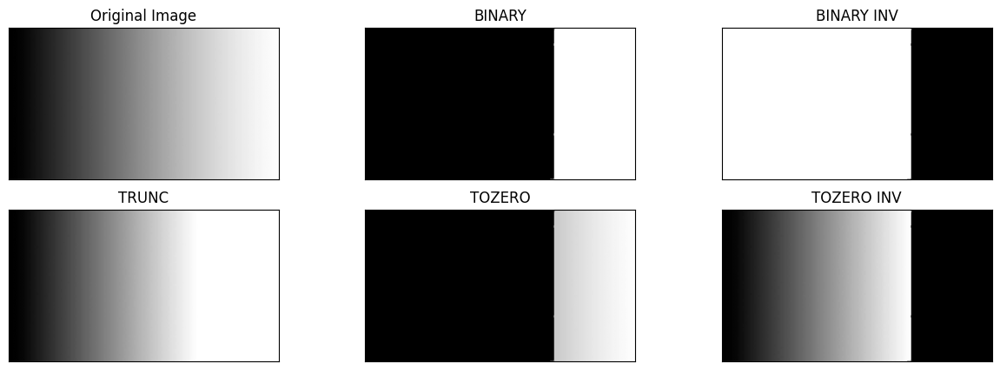

In [14]:
# Soal 3: Global Thresholding Manual dengan thresh = 200
# Asumsi menggunakan citra gradient buatan atau memuat citra gradient
img = cv.imread('/content/drive/MyDrive/PCVK/gradient.jpg', 0)
if img is None: # Jika citra tidak ada, kita buat citra gradient buatan
    img = np.tile(np.linspace(0, 255, 256, dtype=np.uint8), (256, 1))

thresh = 200
maxval = 255

# Implementasi Manual
thresh_binary = np.where(img > thresh, maxval, 0).astype(np.uint8)
thresh_binary_inv = np.where(img > thresh, 0, maxval).astype(np.uint8)
thresh_trunc = np.where(img > thresh, thresh, img).astype(np.uint8)
thresh_tozero = np.where(img > thresh, img, 0).astype(np.uint8)
thresh_tozero_inv = np.where(img > thresh, 0, img).astype(np.uint8)

# Plotting
titles = ['Original Image', 'BINARY', 'BINARY INV', 'TRUNC', 'TOZERO', 'TOZERO INV']
images = [img, thresh_binary, thresh_binary_inv, thresh_trunc, thresh_tozero, thresh_tozero_inv]

plt.figure(figsize=(15, 5))
for i in range(len(images)):
    plt.subplot(2, 3, i+1)
    plt.imshow(images[i], 'gray')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

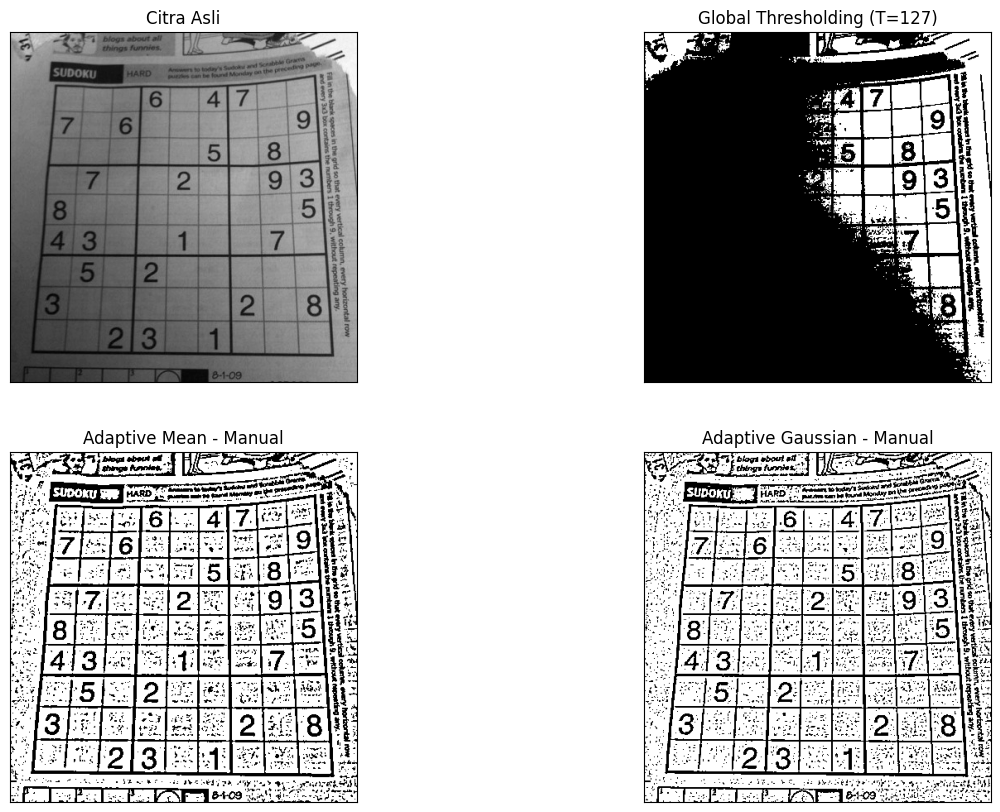

In [15]:
# Soal 4: Adaptive Threshold (Mean & Gaussian) secara manual
img_sudoku = cv.imread('/content/drive/MyDrive/PCVK/sudoku-original.jpg', 0)

if img_sudoku is not None:
    # 1. Global Threshold Manual
    thresh_val = 127
    global_thresh = np.where(img_sudoku > thresh_val, 255, 0).astype(np.uint8)

    # 2. Adaptive Mean Thresholding Manual
    window_size = 11
    C = 2
    pad = window_size // 2
    img_pad = np.pad(img_sudoku, pad, mode='reflect')
    adaptive_mean = np.zeros_like(img_sudoku)

    for i in range(img_sudoku.shape[0]):
        for j in range(img_sudoku.shape[1]):
            window = img_pad[i:i+window_size, j:j+window_size]
            local_mean = np.mean(window)
            if img_sudoku[i, j] > (local_mean - C):
                adaptive_mean[i, j] = 255
            else:
                adaptive_mean[i, j] = 0

    # 3. Adaptive Gaussian Thresholding Manual
    def gaussian_kernel(size, sigma=2):
        x, y = np.mgrid[-size//2 + 1:size//2 + 1, -size//2 + 1:size//2 + 1]
        g = np.exp(-((x**2 + y**2)/(2.0*sigma**2)))
        return g / g.sum()

    g_kernel = gaussian_kernel(window_size, sigma=2)
    adaptive_gauss = np.zeros_like(img_sudoku)

    for i in range(img_sudoku.shape[0]):
        for j in range(img_sudoku.shape[1]):
            window = img_pad[i:i+window_size, j:j+window_size]
            local_gauss_mean = np.sum(window * g_kernel)
            if img_sudoku[i, j] > (local_gauss_mean - C):
                adaptive_gauss[i, j] = 255
            else:
                adaptive_gauss[i, j] = 0

    # Plotting
    titles = ['Citra Asli', 'Global Thresholding (T=127)', 'Adaptive Mean - Manual', 'Adaptive Gaussian - Manual']
    images = [img_sudoku, global_thresh, adaptive_mean, adaptive_gauss]

    plt.figure(figsize=(15, 10))
    for i in range(len(images)):
        plt.subplot(2, 2, i+1)
        plt.imshow(images[i], 'gray')
        plt.title(titles[i])
        plt.xticks([]), plt.yticks([])
    plt.show()
else:
    print("Pastikan path gambar sudoku-original.jpg sudah benar.")

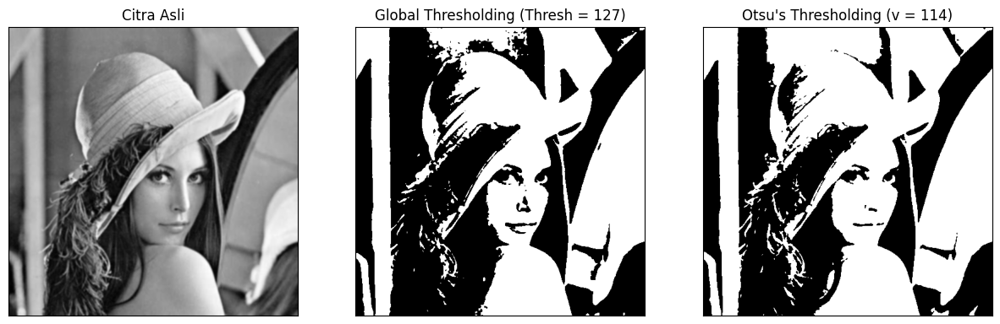

In [16]:
# Soal 5A: Otsu Manual
filename = '/content/drive/MyDrive/PCVK/lena.jpg'
img_lena = cv.imread(filename, 0)

if img_lena is not None:
    blur = cv.GaussianBlur(img_lena, (5,5), 0)
    thresh = 127

    def otsu_manual(gray):
        pixel_number = gray.shape[0] * gray.shape[1]
        mean_weight = 1.0 / pixel_number
        his, bins = np.histogram(gray, np.arange(0, 257))
        final_thresh = -1
        final_value = -1
        intensity_arr = np.arange(256)

        for t in bins[1:-1]:
            pcb = np.sum(his[:t])
            pcf = np.sum(his[t:])
            if pcb == 0 or pcf == 0:
                continue
            Wb = pcb * mean_weight
            Wf = pcf * mean_weight
            mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)
            muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)

            # Between Class Variance
            value = Wb * Wf * (mub - muf) ** 2

            if value > final_value:
                final_thresh = t
                final_value = value

        final_img = gray.copy()
        final_img[gray > final_thresh] = 255
        final_img[gray <= final_thresh] = 0
        return final_img, final_thresh

    otsu_biner, otsu_thresh_val = otsu_manual(blur)

    # Threshold Global Library untuk perbandingan
    ret, th1 = cv.threshold(blur, thresh, 255, cv.THRESH_BINARY)

    x = f"Otsu's Thresholding (v = {otsu_thresh_val})"
    titles = ['Citra Asli', f'Global Thresholding (Thresh = {thresh})', x]
    citra3 = [blur, th1, otsu_biner]

    plt.figure(figsize=(15, 5))
    for i in range(len(citra3)):
        plt.subplot(1, 3, i+1)
        plt.imshow(citra3[i], 'gray')
        plt.title(titles[i])
        plt.xticks([]), plt.yticks([])
    plt.show()

# JAWABAN PERTANYAAN 5A:
# Hasil Binary Thresholding dengan T=127 bernilai 0 (hitam semua) karena pada
# citra Lena yang digunakan (low contrast), intensitas pikselnya berkisar
# antara 85 hingga 108. Karena batas ambang (127) lebih besar dari semua
# nilai intensitas piksel, tidak ada piksel yang memenuhi syarat menjadi putih.
# Angka ambang yang ideal agar gambar masih terlihat ada di sekitar nilai 92-93
# (sesuai hasil algoritma Otsu).

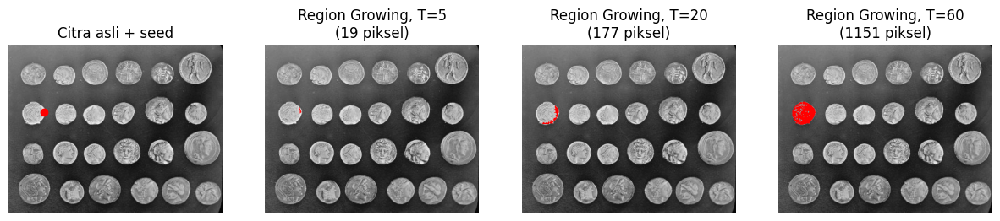

In [17]:
# Soal 6B: Segmentasi menggunakan fungsi flood skimage
gray_coins = data.coins()
seed = (121, 63) # (baris, kolom)

tolerances = [5, 20, 60]
plt.figure(figsize=(15, 5))

# Plot gambar asli dengan seed point
plt.subplot(1, 4, 1)
plt.imshow(gray_coins, cmap='gray')
plt.plot(seed[1], seed[0], 'ro') # Menandai seed
plt.title('Citra asli + seed')
plt.axis('off')

for idx, tol in enumerate(tolerances):
    region = flood(gray_coins, seed_point=seed, tolerance=tol, connectivity=1)

    # Buat mask merah untuk menyorot region
    img_colored = color.gray2rgb(gray_coins)
    img_colored[region] = [255, 0, 0] # Highlight region dengan merah

    plt.subplot(1, 4, idx + 2)
    plt.imshow(img_colored)
    plt.title(f'Region Growing, T={tol}\n({np.sum(region)} piksel)')
    plt.axis('off')

plt.show()

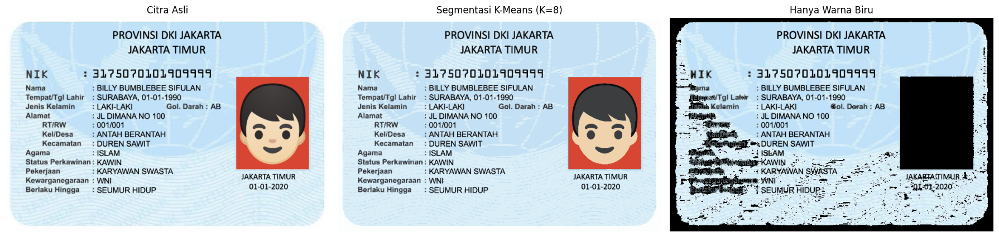

In [18]:
# Soal 7: Segmentasi warna K-Means (K=8) dan memunculkan warna biru saja
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Asumsikan ktp_fulan.jpg telah diupload ke colab/drive
img_ktp = cv.imread('/content/drive/MyDrive/PCVK/ktp_fulan.jpg')

if img_ktp is not None:
    # Convert ke RGB untuk visualisasi yang benar di Matplotlib
    img_ktp_rgb = cv.cvtColor(img_ktp, cv.COLOR_BGR2RGB)

    # 1. Segmentasi K-Means (K=8)
    Z = img_ktp_rgb.reshape((-1, 3))
    Z = np.float32(Z)

    k = 8
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(Z)

    centers = np.uint8(kmeans.cluster_centers_)
    labels = kmeans.labels_

    segmented_kmeans = centers[labels.flatten()]
    segmented_kmeans_img = segmented_kmeans.reshape(img_ktp_rgb.shape)

    # 2. Filter Hanya Warna Biru menggunakan HSV
    img_ktp_hsv = cv.cvtColor(img_ktp, cv.COLOR_BGR2HSV)
    H, S, V = cv.split(img_ktp_hsv)

    # Rentang biru KTP sesuai modul
    mask_biru = ((H >= 85) & (H <= 130) & (S >= 25) & (V >= 40))

    # Menerapkan mask ke citra (area di luar mask biru akan menjadi hitam)
    ktp_biru_saja = np.zeros_like(img_ktp_rgb)
    # Anda juga dapat menerapkan mask ini ke 'segmented_kmeans_img' jika ingin warna solid
    ktp_biru_saja[mask_biru] = img_ktp_rgb[mask_biru]

    # 3. Plotting Hasil menjadi 3 kolom
    plt.figure(figsize=(18, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(img_ktp_rgb)
    plt.title('Citra Asli')
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(segmented_kmeans_img)
    plt.title('Segmentasi K-Means (K=8)')
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(ktp_biru_saja)
    plt.title('Hanya Warna Biru')
    plt.axis('off')

    plt.tight_layout()
    plt.show()
else:
    print("Pastikan path gambar ktp_fulan.jpg sudah benar.")

In [19]:
# Instalasi Tesseract OCR (Jalankan cell ini terlebih dahulu)
!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


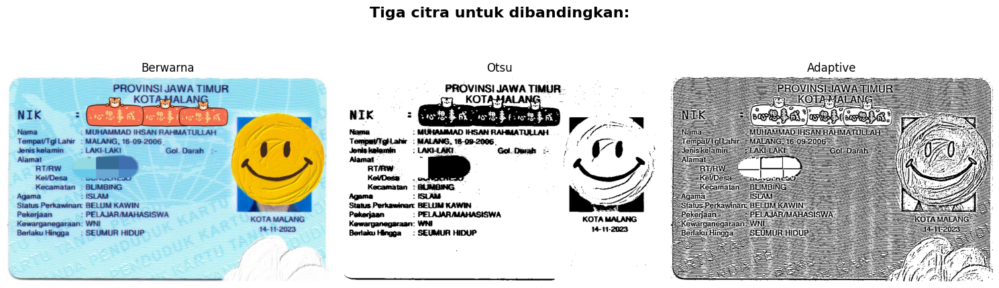

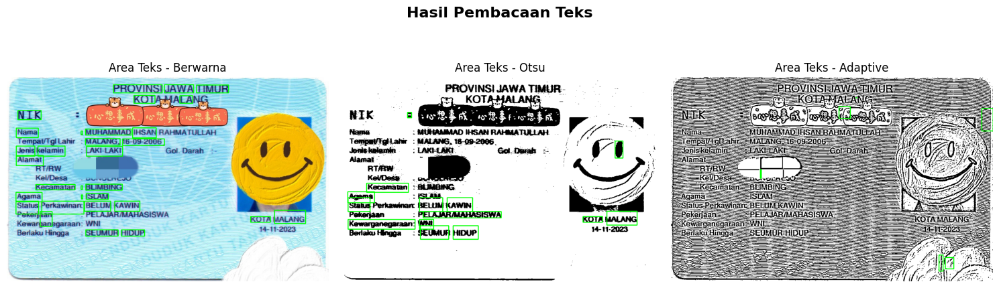


========== BERWARNA ==========
PROVINSI JAWA HMUR
KOT LA
NIK :
Nama : MUHAMMAD IHSAN RAHMATULLAH
Tempat'Tgilahir : MALANG, 16-09-2006
Jenis kelamin 1 LAKI-LAKI Gol. Darah --
Alamat ai
mt...
Kel/Desa
Kecamatan : BLIMBING
Agama 2 ISLAM
Status Perkawinan BELUM KAWIN 1
Aa — —— —— KOTA MALANG
Berlaku Hingga: SEUMUR HIDUP 2 —
an


========== OTSU ==========
. PROVINSIJAWATIMUR- —
De MKKS URYNANG :
RIK ' z Pn NS PA ANN AN - .. 8. |
Joniskadamin.—: LAKHIAKI GolDaah — ) ni
ai FN
Kecamatan "ADNBNG : - 4 " —
Agama 1 ISLAKG : | 1
Status Perkawinamt BELUM KAWIN rp
Pekerjaa : PELAJARAMAHASISWA KOTA MALANG
Kewarganegaraan: WNI n
Berlaku Hingga: SEUMUR HIDUP 14-11-2023
Bm


========== ADAPTIVE ==========
———— 5 ee

Pn YINSE ANA MERASA
, AA :3 5 TA
Ep KOHMALANG aa
P5 AE E

PA ——5 2 aa Lan “ra AS
AN anang |
E Tempati TAEANG 16 092006 1 AA ANN
4 5 PA AI Me LANANG:
“ So Diah un On
EA ama Ian —————— IN MP NYA MAA Pe GAN Sh
e/De : | - L NN Nanga DNA
Pe en Nae ja
“Saus Pekan DELIMKAMIN oo kg

Tani AA KE IT 

In [24]:
# import pytesseract
# from pytesseract import Output
# # UBAH path ini sesuai dengan letak gambar KTP yang Anda gunakan
# img_path = '/content/drive/MyDrive/PCVK/Image/244107020218/Ktp_Ihsan.jpeg'
# img = cv.imread(img_path)

# if img is not None:
#     # 1. Siapkan tiga citra untuk dibandingkan
#     img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
#     img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

#     # Segmentasi Otsu
#     _, img_otsu = cv.threshold(img_gray, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

#     # Segmentasi Adaptive
#     img_adaptive = cv.adaptiveThreshold(img_gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 11, 2)

#     # TAMPILAN 1: Tiga Citra untuk dibandingkan
#     fig, axes = plt.subplots(1, 3, figsize=(15, 5))
#     fig.suptitle('Tiga citra untuk dibandingkan:', fontsize=16, fontweight='bold', ha='center')

#     axes[0].imshow(img_rgb)
#     axes[0].set_title('Berwarna')
#     axes[0].axis('off')

#     axes[1].imshow(img_otsu, cmap='gray')
#     axes[1].set_title('Otsu')
#     axes[1].axis('off')

#     axes[2].imshow(img_adaptive, cmap='gray')
#     axes[2].set_title('Adaptive')
#     axes[2].axis('off')
#     plt.tight_layout()
#     plt.show()

#     # 2. Fungsi Pembacaan Teks dan Kotak Hijau (Confidence > 60)
#     custom_config = r'-l ind --psm 6'

#     def draw_boxes(image, is_gray=False):
#         # Convert ke RGB agar kotak hijaunya berwarna (bukan abu-abu)
#         if is_gray:
#             img_draw = cv.cvtColor(image, cv.COLOR_GRAY2RGB)
#         else:
#             img_draw = image.copy()

#         # Ekstrak data menggunakan image_to_data
#         d = pytesseract.image_to_data(image, config=custom_config, output_type=Output.DICT)
#         n_boxes = len(d['text'])
#         confidences = []

#         for i in range(n_boxes):
#             conf = int(d['conf'][i])
#             # Hanya gambar kotak jika nilai confidence lebih dari 60
#             if conf > 60:
#                 (x, y, w, h) = (d['left'][i], d['top'][i], d['width'][i], d['height'][i])
#                 img_draw = cv.rectangle(img_draw, (x, y), (x + w, y + h), (0, 255, 0), 2)
#                 confidences.append(conf)

#         # Hitung rata-rata confidence untuk kebutuhan tabel di akhir
#         avg_conf = np.mean(confidences) if confidences else 0
#         return img_draw, avg_conf

#     img_box_color, conf_color = draw_boxes(img_rgb, is_gray=False)
#     img_box_otsu, conf_otsu = draw_boxes(img_otsu, is_gray=True)
#     img_box_adaptive, conf_adaptive = draw_boxes(img_adaptive, is_gray=True)

#     # TAMPILAN 2: Hasil Pembacaan Teks (Area Teks Kotak Hijau)
#     fig2, axes2 = plt.subplots(1, 3, figsize=(15, 5))
#     fig2.suptitle('Hasil Pembacaan Teks', fontsize=16, fontweight='bold', ha='center')

#     axes2[0].imshow(img_box_color)
#     axes2[0].set_title('Area Teks - Berwarna')
#     axes2[0].axis('off')

#     axes2[1].imshow(img_box_otsu)
#     axes2[1].set_title('Area Teks - Otsu')
#     axes2[1].axis('off')

#     axes2[2].imshow(img_box_adaptive)
#     axes2[2].set_title('Area Teks - Adaptive')
#     axes2[2].axis('off')
#     plt.tight_layout()
#     plt.show()

#     # 3. Cetak Hasil Pembacaan Teks (Contoh Hasil Pembacaan)
#     text_color = pytesseract.image_to_string(img_rgb, config=custom_config)
#     text_otsu = pytesseract.image_to_string(img_otsu, config=custom_config)
#     text_adaptive = pytesseract.image_to_string(img_adaptive, config=custom_config)

#     print("\n========== BERWARNA ==========")
#     print(text_color)

#     print("\n========== OTSU ==========")
#     print(text_otsu)

#     print("\n========== ADAPTIVE ==========")
#     print(text_adaptive)

#     # Bantuan untuk mengisi tabel analisis (menghitung rata-rata confidence secara otomatis)
#     print("\n" + "="*50)
#     print("Rata-rata Confidence (Nilai Confidence > 60):")
#     print("="*50)
#     print(f"Berwarna Asli       : {conf_color:.2f}%")
#     print(f"Segmentasi Otsu     : {conf_otsu:.2f}%")
#     print(f"Segmentasi Adaptive : {conf_adaptive:.2f}%")
#     print("="*50)

# else:
#     print("Gambar tidak ditemukan. Pastikan path gambar Anda sudah benar.")


Memproses: Anggota 1


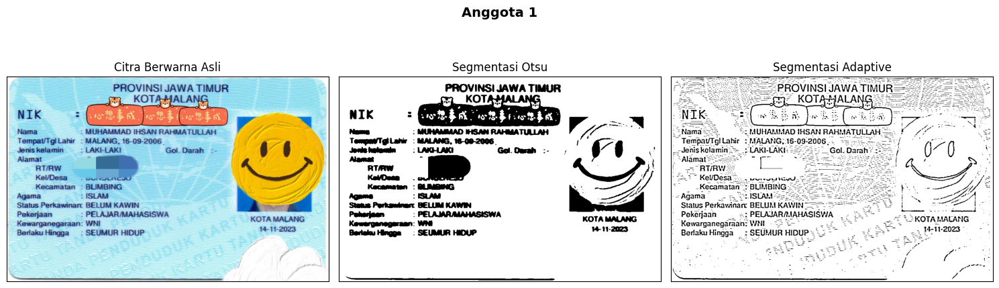

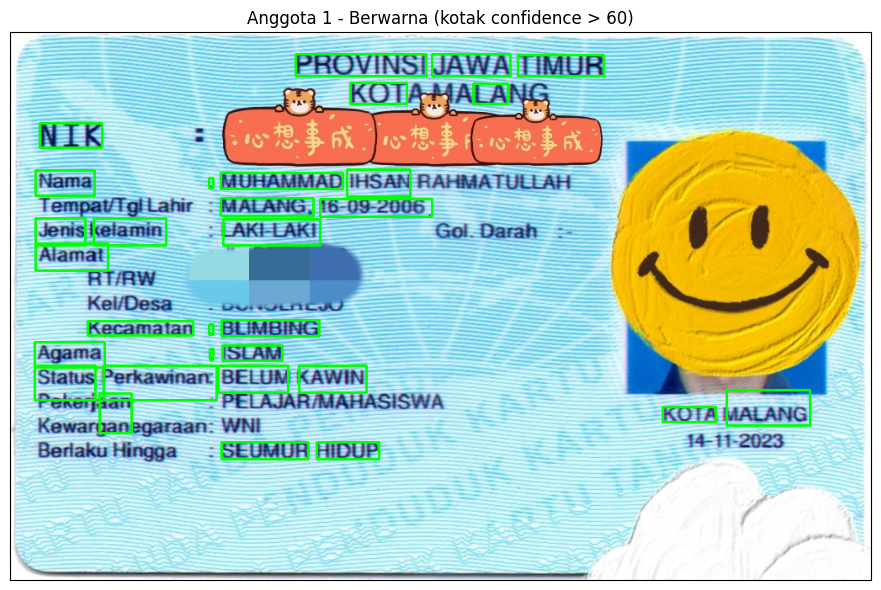


--- OCR Berwarna ---
PROVINSI JAWA HMUR
KOT LA
NIK :
Nama : MUHAMMAD IHSAN RAHMATULLAH
Tempat'Tgilahir : MALANG, 16-09-2006
Jenis kelamin 1 LAKI-LAKI Gol. Darah --
Alamat ai
mt...
Kel/Desa
Kecamatan : BLIMBING
Agama 2 ISLAM
Status Perkawinan BELUM KAWIN 1
Aa — —— —— KOTA MALANG
Berlaku Hingga: SEUMUR HIDUP 2 —
an



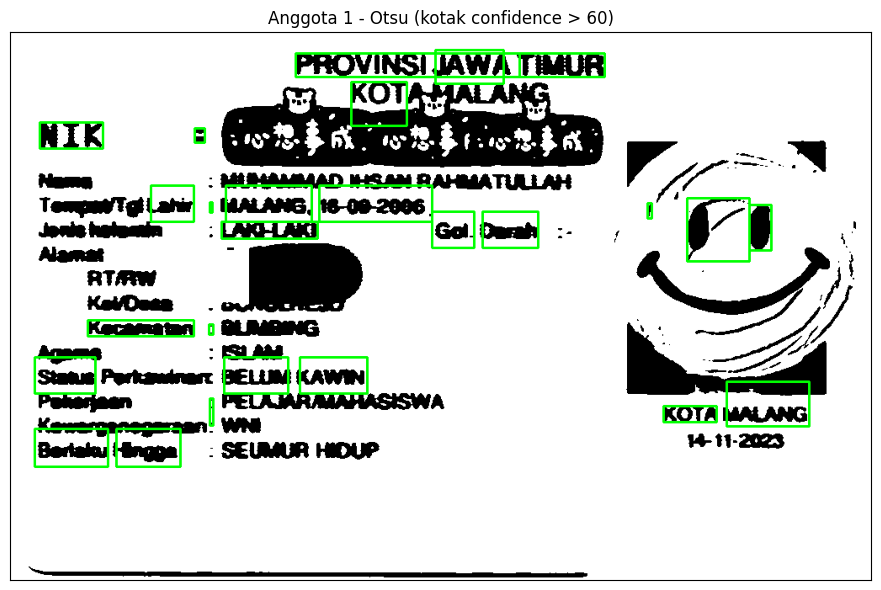


--- OCR Otsu ---
PROVINSI JAWA TIMUR
sha KOT UV mnta YR
NIK 3 “al S1 INN ON - 8 |
Ma MANA po
Temput/Tgi Lahir : MALANG, 16-00-2006. / r
Jenehalamin ——: LAKI-LAKI Gol. Darah :-— ' 1
“—.. HD)
Kecamatan : BUMDING 2.
Status Perkawinan BELUM KAWIN Ps
Pekerjaan : PELAJARAMAHASISWA KOTA MALANG
Bertaku Hingga H SEUMUR HoUP Hina
Na 5.



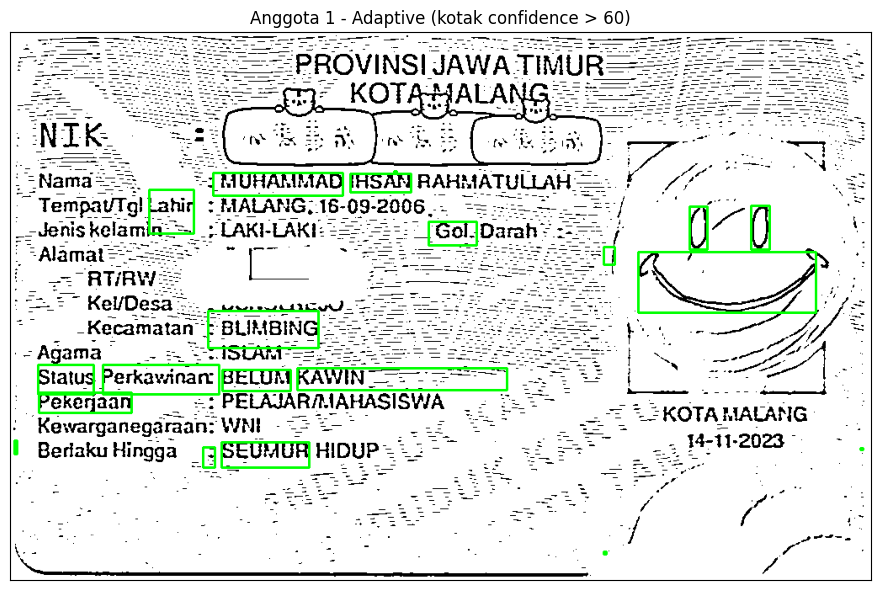


--- OCR Adaptive ---
—L SEA - : ———-: ba NP
'5Nama s4 ——z MUHAMMAD IHSAN BAHMATULLAH-—-. Vo 7” 3
| TempauTg Lahir MALANG: 16-09-2006,- “Ss. is) "an 8
. denis kelamin ./ LAKKKAKI: 55. 55-:7 “Gol. Darah 2 0 0 &
(Alamat es 1 pt SE NE SSE | ' No
am Lo RA Phi
(F3 Ke/DesA 5. woven LES Anas an A.A “72
#0 Kecamatan #BUMBING Leo AE PA — of 5
-Agama —. » TLISLAM aa ena | NG AIA
Status Perkawinan: BELUM KAWIN —T— TE gan ia | 5 “TT 2

' Pekerjaan — -: PELAJARIMAHASISWA .- txt” TTS EGA AKAN

: “Kewarganegaraan: WM! 5 E— er aa La i.20o3 aa
| BerlakuHingga : SEUMUR HIDUP s2” AS 5 :
Na Oa aa SE LE na Pat -
Ki Tn PPN Te . 1 pe


Memproses: Anggota 2


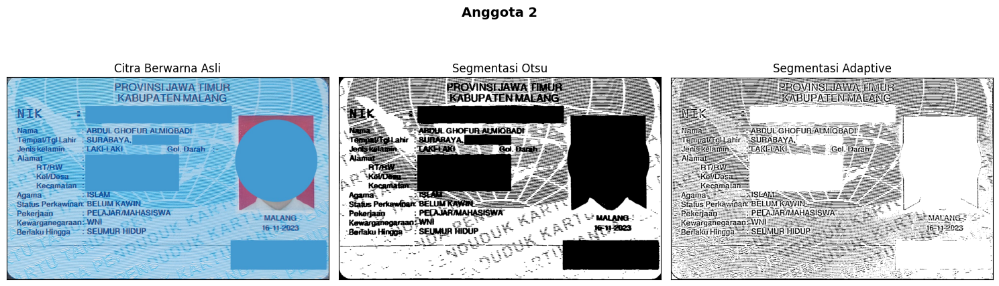

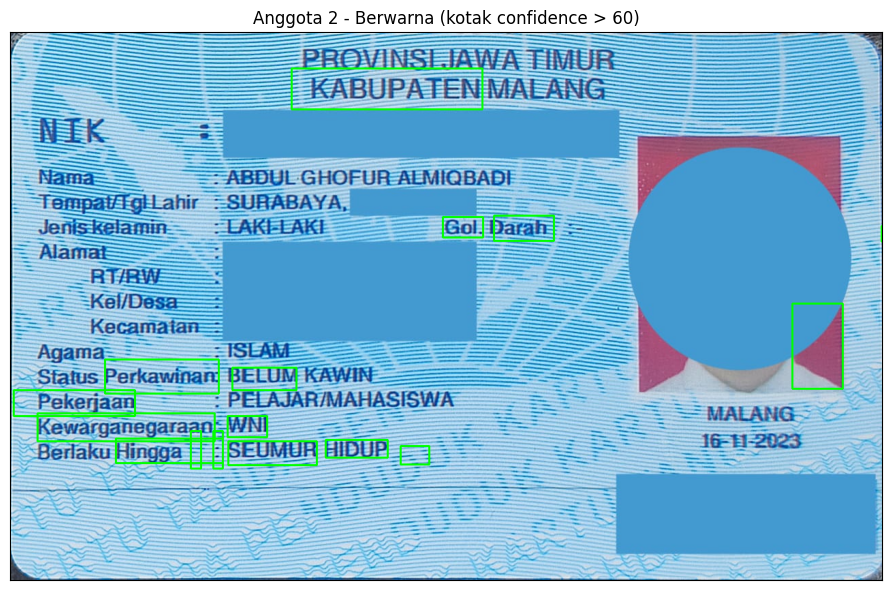


--- OCR Berwarna ---
BE aa
BE” KABUPATEN MAPANG
P5 — 5——————————

Kama oo ABDUL GHOFURALMIOBADI 5 ” 2
- Sfampattgilahir 2SURABAYA, PE —— AP
Jeniskelamn -LAKETAKI A Gol. Darah 2 |
Alamak. M—— —— ——- FP
5-5 SKaj/Desa — 2 2
Agama ISA S2 2 4
“Status Perkawinan BELUM KAMAIN ———— —. — -“
“Pekerjaan - — :PELAJARMAHASISWA 5 —..- 5
Kewarganegaraan WNI AAA 5 MAEANG-—
“Beraku Hingga — : SEUMUR HIDUP — 2 2 EH 2023
: -—- 5 : ———



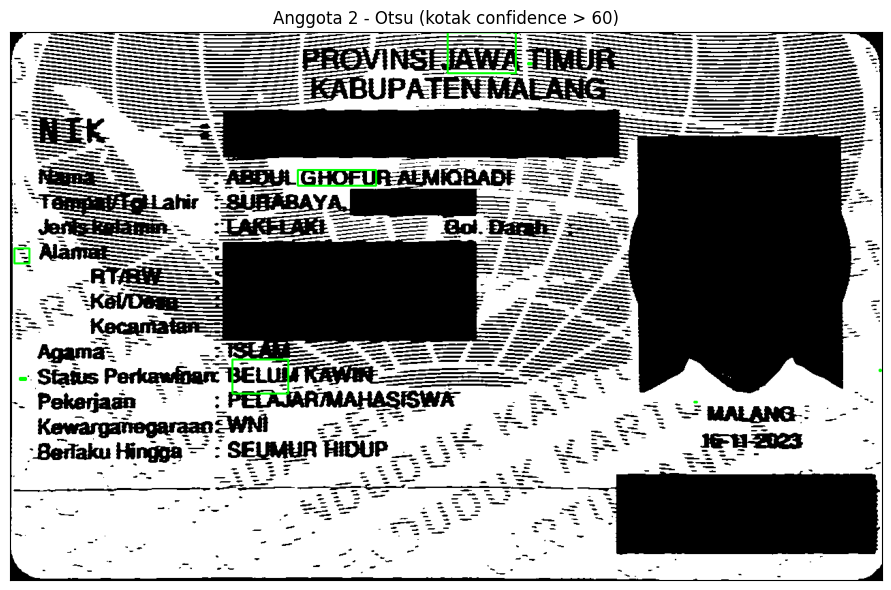


--- OCR Otsu ---
——555-320.-:.——- 555—5-: s5: z—:55— —— h,
BA NONINSI JAWA MU &
PP NSEJAMAR : 5

ES EPA EL —.

5 Se  SABUPATENMAPANG |
2 SE —— £ km —5 e—

Ty 5 as —

Sek — ee .
PN Pe ——3 AE TS

. RR 2 ABDI GHOFU FOBADF PE -

2 Mama ———3— -

k AE 3

an —— 2 z
2 Keoeme S5 | E

RE —— TE. .

aa — Aa PA

— Agama. £—— Pe TA |
- Status Perkawihamt BELUM KAWIN ————— - Sa | .

. Pekerjaan EPELAJARMMAHASISWA DLP s3 H MALANG: .-
Kewargarregaraan? SE TS a N
“Bertaku Hingga SELMUA MADUP sa ia



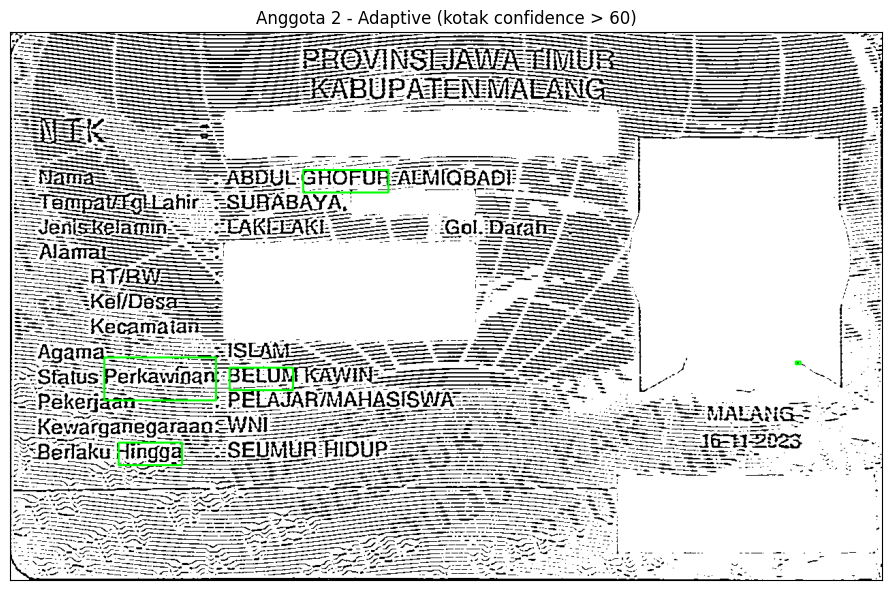


--- OCR Adaptive ---
3 3——5—33——————————5z5:555zz.-..-t3——@-Z3
5 5 —— TOVINS aa AA ES PA
As ——— AAA an Sa AA

EP” KABUPATENMALANG EP |
aa — TEE —- :
PE 5 &€ Le Ku 2:
Nama 3“ ABDUL GHOFUR AEMIOBADI SEX Po
— Tampartgilahir 3SUBABAYA, 2322 “| e—
EA FP — FE
PG —— FT Es 2 Pt
PN — Ea — 1 Pe
Dan aKel/Desa mM j Ne
Ea Kecamaiana TE ag
SAgamass SISA 2 | oo. .
#Sfalus Perkawinan BELUM KAM
E-pekerjaane 2 —— 2PELAJAH/MAHASISWA Na
E Kewarganegaraan WN SS 5 us MALANGY 2

SeKewarganegaraan SN Ke etiSnos
“Epertaku Hingga 22 SEUMUR HIDUP 2 EN


Memproses: Anggota 3


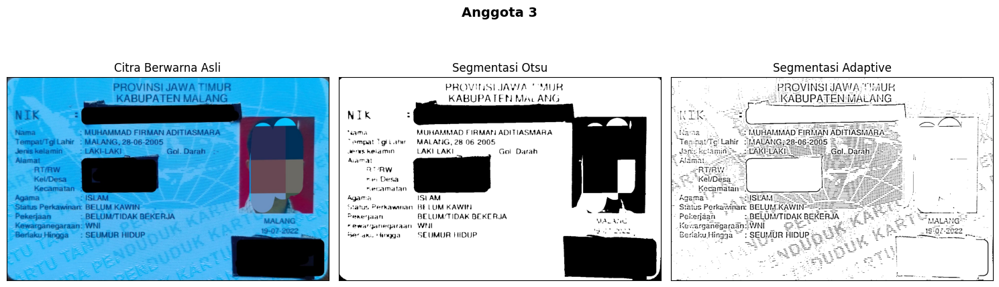

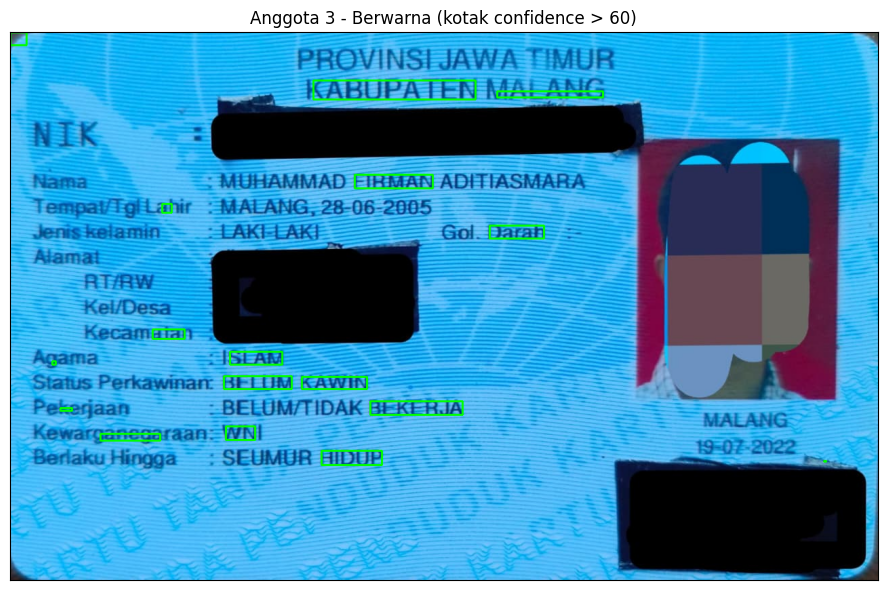


--- OCR Berwarna ---
£ —3
KABUPATEN MALANG
MUHAMMAD FIRMAN ADFFASMAR7
af MAEANG:-28-06-2905
h AKA sol. Darah
ataf «
J SEAM
erkawinan BELUM KAWIN
ke BEEUM/TIDAK BEKERJA
- janega | WN -
h dngg SEHMER HIDUP | 7



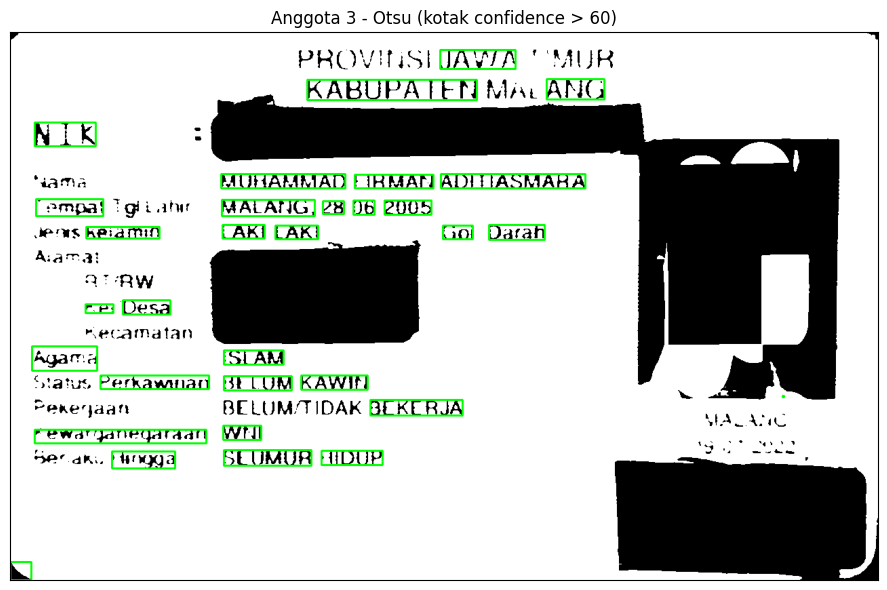


--- OCR Otsu ---
P 1
PROVIUSI JAWA "'MUR
KABUPATEN Mp4 ANG
NIK :
ama MUHAMMAD FIRMAN ADITIASMARA
Tempat 'giiahur MALANG, 28 06 2905
Jeras kelamin LAKI LAKI Gol Darah
Alamat
AT RW
re: Desa
secamatan
Agama ISLAM
Status Perkawnan BELUM KAWIN - ,
Pekegaan BELUM,/TIDAK BEKERJA MALANG
“ewaryanegaraan WII ai “ 1 an
Beam Hingga SEUMUR HIDUP Makau
“ 0)



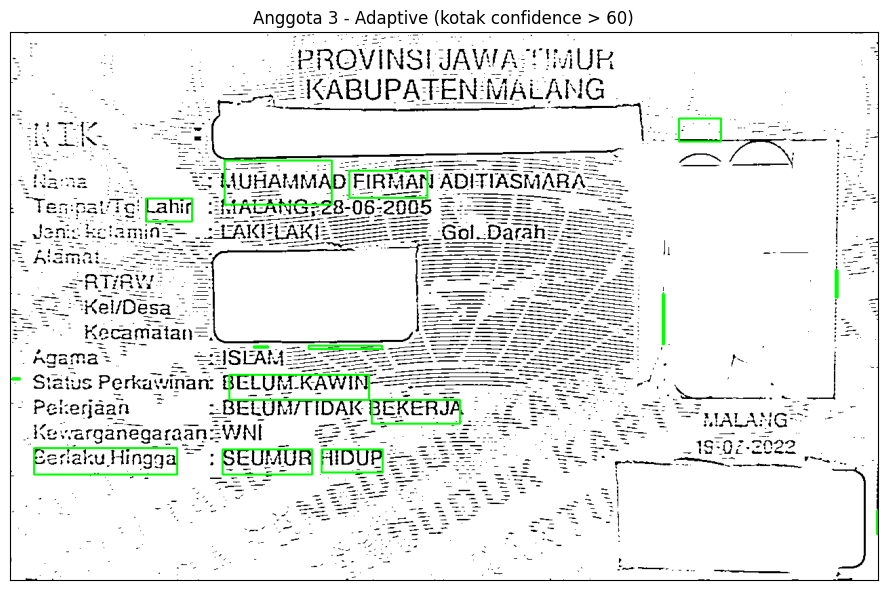


--- OCR Adaptive ---
He BROVINSI JAWA IMUR .
Nan “553 KABUPATENMALANG : £
en ss — AA
Be in SS —— 5 —— ra — Hi
LHbma 035 MUHAMMAD FIRMAN ADITIASMARA-—— Pb
. “Tenpar'igi Lahir EMAEANGz28-05:2005 Ana 5 |.
DLARUAN ae |
. TE Kel/Desa Pe | 1
En Kecamiatan-, — —— LA ' 3
DAgamar —. SEISEAM PE BE SESI Lo |:
— Status Perkawinan: BELUM-KAWIN EPA RM
“ Pekejaan ——— 2BELUM/TIDAK BEKERJA 2.25 PES arang 2
Kerargan esa AAN Ans E ES as MET aghaanoo
| BerlakuHingga — : SEUMUR HIDUP 2555 Te AR
Ka Be
NN ea an |


Memproses: Anggota 4


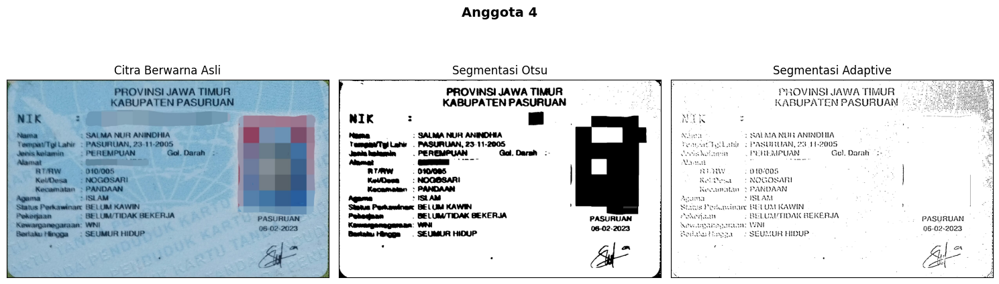

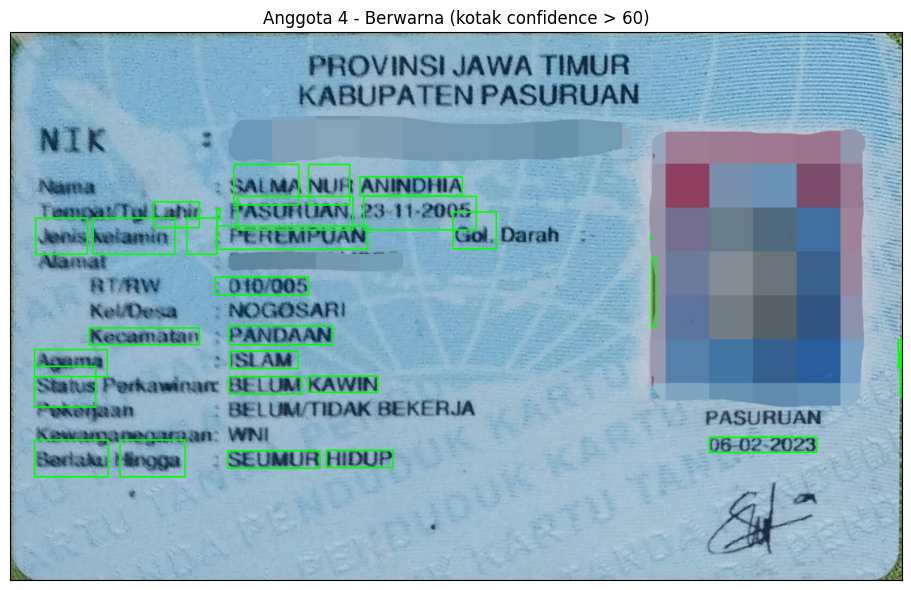


--- OCR Berwarna ---
se SP
“Ga (EL KABUPATENPASURYAN
Nara 2 SALMA NUR ANINDHIA e N 2
Tampan Tpi Lahir : PASURUAN, 23-11-2005 —— -
Jenis kelamin — PEREMPUAN Ga. Darah | 5
RTRW: 010/005 mena | »
Kecamatan - PANDAAN a Er | :
Agama 2 ISLAM SAN An |
Status Perkawinam BELUM KAWIN |
Lena si BELAPOAK BEKERJA ! Hmmm —
Beriaku Hingga —: SEUMUR HIDUP 06-02-2023



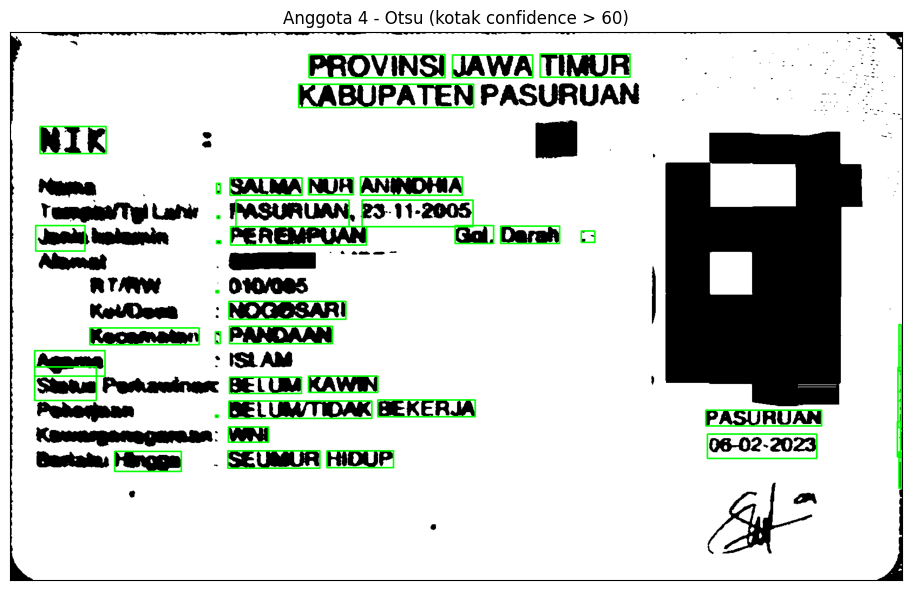


--- OCR Otsu ---
Temuan anna naa ana en an nn 5 ks ON
PROVINSI JAWA TIMUR 2. ai
KABUPATEN PASURUAN Mm
NIK z n "
Nama. : SALMA NUR ANINDHIA
Temgua/Tgi Lah . PASURUAN, 23-11-2005
Janda alamin . PEREMPUAN Gol. Darah :-
Alamat .——.—..
NT AM : 0W/085
Kelam —: NOGOSARI
Kecamatan : PANDAAN |
Agama "ISLAM |
Sintus Perhawinax BELUM KAWIN ' |
Peharjaan . BELUM/TIDAK BEKERJA PASURUAN |
Kamusgangaaan: WNI 06-02-2023 |
Bastatu Hingga —. SEUMUR HIDUP |
0 EN



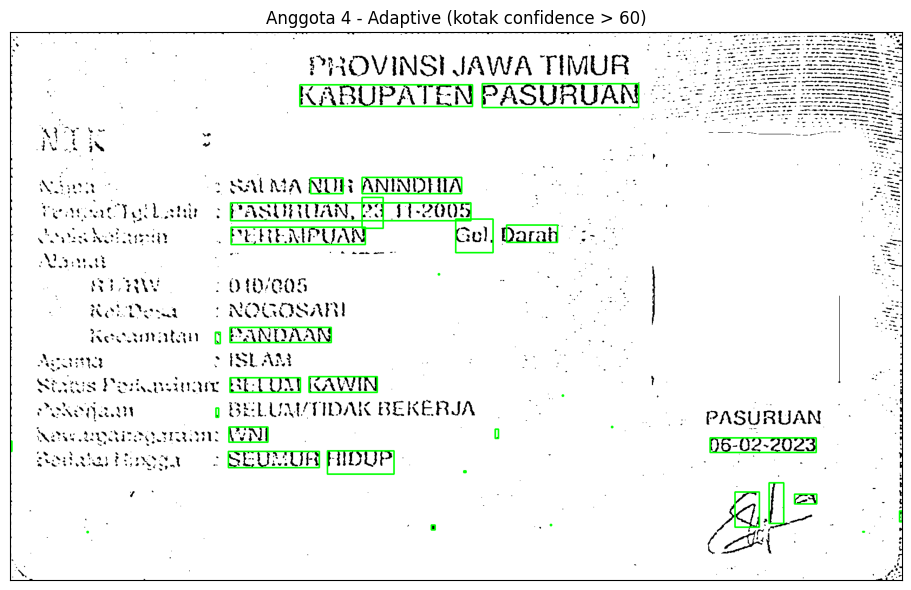


--- OCR Adaptive ---
5. | KABUPATEN PASURUAN ena.
Nda "5 SAUMA NUR ANINDHIA benar P3
| TenyatTullahh 2 PASURUAN, 23 112005 Ba NN:
| Sesekalamir 0. PEREMPUAN Gol, Darah “:- LL
— Ngnar 0 Mean Tn 1
D0 RERW Oth/gas | Na 2
P0 Rei NOGOWARI Na Na
: Kensumatah 1 PANDAAN Hah ji
| AKG ISLAM : NN NN 1
| Status Prukadoant BELUM KAWIN | Tn) SN
| Peksijaam : BELUMITIDAK BEKERJA | PASURYAN
| Kesadand ea WNI . | , :
| Sai " 06-02-2023 :
— Kemaka Hung SEUMUR HIDUP | : Pen Nan -
: n 4, | A ag
— po , . AH :
, . . " Cr . '
NT . . Ma PN


TABEL PERBANDINGAN: Anggota 1


,No,Teks Sebenarnya,OCR Berwarna,OCR Otsu,OCR Adaptive
0,1,PROVINSI,PROVINSI,PROVINSI,woven
1,2,DKI,KAWIN,KAWIN,Ki
2,3,JAKARTA,JAWA,JAWA,AKAN
3,4,TIMUR,HMUR,TIMUR,SEUMUR
4,5,NIK,NIK,NIK,denis
5,6,Nama,Nama,Ma,'5Nama
6,7,Alamat,Alamat,Kecamatan,(Alamat
7,8,Agama,Agama,Ma,-Agama
8,9,Berlaku,Berlaku,Bertaku,BerlakuHingga
9,10,SEUMUR,SEUMUR,SEUMUR,SEUMUR



Ringkasan Anggota 1:


,Metode,Item Tepat,Kecocokan (%),Rata-rata Confidence
0,Berwarna,7,70.0%,86.65
1,Otsu,4,40.0%,87.65
2,Adaptive,1,10.0%,81.95



TABEL PERBANDINGAN: Anggota 2


...


Ringkasan Anggota 4:


,Metode,Item Tepat,Kecocokan (%),Rata-rata Confidence
0,Berwarna,2,20.0%,83.00
1,Otsu,6,60.0%,85.55
2,Adaptive,1,10.0%,80.28



RINGKASAN KELOMPOK (4 ANGGOTA)


,Anggota,Metode,Item Tepat (dari 10),Kecocokan (%),Rata-rata Confidence
0,Anggota 1,Berwarna,7,70.0%,86.65
1,Anggota 1,Otsu,4,40.0%,87.65
2,Anggota 1,Adaptive,1,10.0%,81.95
3,Anggota 2,Berwarna,2,20.0%,77.88
4,Anggota 2,Otsu,0,0.0%,85.62
5,Anggota 2,Adaptive,2,20.0%,72.20
6,Anggota 3,Berwarna,0,0.0%,84.12
7,Anggota 3,Otsu,4,40.0%,85.94
8,Anggota 3,Adaptive,1,10.0%,86.07
9,Anggota 4,Berwarna,2,20.0%,83.00



JAWABAN PERTANYAAN ANALISIS D2

1. Citra masukan mana yang menghasilkan pembacaan paling tepat?
   Tunjukkan buktinya dari tabel.

   JAWABAN:
   Berdasarkan tabel ringkasan kelompok, citra [BERWARNA/OTSU/ADAPTIVE]
   menghasilkan kecocokan tertinggi yaitu [X]% (rata-rata [Y] item tepat
   dari 10). Hal ini terlihat pada anggota [nama anggota] yang mendapat
   [Z] item tepat dengan metode tersebut, dibandingkan [A] item pada
   metode lain.

   Bukti dari tabel:
   - Berwarna : rata-rata [..]% kecocokan
   - Otsu     : rata-rata [..]% kecocokan
   - Adaptive : rata-rata [..]% kecocokan


2. Sebutkan minimal dua kesalahan pembacaan.

   JAWABAN:
   a) [Contoh 1]: Pada citra [tipe] anggota [nama], teks "[sebenarnya]"
      terbaca sebagai "[hasil OCR]". Ini terjadi karena [alasan: huruf
      tipis / noise / kontras rendah / font kecil].

   b) [Contoh 2]: Pada citra [tipe] anggota [nama], angka "[sebenarnya]"
      terbaca sebagai "[hasil OCR]". Pola kesalahan umum: 1↔I, 0↔O,
      8↔B

In [28]:
import pytesseract
from pytesseract import Output
from difflib import SequenceMatcher
def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0 / pixel_number
    his, bins = np.histogram(gray, np.arange(0, 257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)
    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        if pcb == 0 or pcf == 0:
            continue
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight
        mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2
        if value > final_value:
            final_thresh = t
            final_value = value
    final_img = gray.copy()
    final_img[gray >  final_thresh] = 255
    final_img[gray <= final_thresh] = 0
    return final_img, final_thresh

# ---------- Adaptive manual ----------
def konvolusi_manual(citra, kernel):
    citra = citra.astype(np.float32)
    kh, kw = kernel.shape
    ph, pw = kh // 2, kw // 2
    H, W = citra.shape
    padded = np.pad(citra, ((ph, ph), (pw, pw)), mode='reflect')
    hasil = np.zeros((H, W), dtype=np.float32)
    for i in range(kh):
        for j in range(kw):
            hasil += kernel[i, j] * padded[i:i + H, j:j + W]
    return hasil


def buat_kernel_gaussian(b, sigma):
    r = b // 2
    x = np.arange(-r, r + 1)
    kernel = np.exp(-(x[:, None] ** 2 + x[None, :] ** 2) / (2 * sigma ** 2))
    return kernel / kernel.sum()


def adaptive_manual(gray, b=31, C=10, gaussian=True, sigma=2):
    if gaussian:
        kernel = buat_kernel_gaussian(b, sigma)
    else:
        kernel = np.ones((b, b), dtype=np.float32) / (b * b)
    rata_lokal = konvolusi_manual(gray, kernel)
    ambang_lokal = rata_lokal - C
    return np.where(gray > ambang_lokal, 255, 0).astype(np.uint8)


# ---------- Bangun 3 citra dari 1 KTP ----------
def buat_tiga_citra(filename):
    img_berwarna = cv.cvtColor(cv.imread(filename), cv.COLOR_BGR2RGB)
    gray = cv.cvtColor(img_berwarna, cv.COLOR_RGB2GRAY)
    blur = cv.GaussianBlur(gray, (5, 5), 0)

    otsu_img, _ = otsu(blur)
    adaptive_img = adaptive_manual(blur, b=31, C=10, gaussian=True, sigma=2)

    return img_berwarna, otsu_img, adaptive_img


# ---------- OCR + gambar kotak hijau ----------
LANG = 'ind'
PSM = '--psm 6'
MIN_CONF = 60


def baca_ocr(citra):
    teks = pytesseract.image_to_string(citra, lang=LANG, config=PSM)
    detail = pytesseract.image_to_data(citra, lang=LANG, config=PSM,
                                       output_type=Output.DICT)
    return teks, detail


def gambar_kotak(citra, detail, min_conf=MIN_CONF):
    hasil = citra.copy()
    if len(hasil.shape) == 2:
        hasil = cv.cvtColor(hasil, cv.COLOR_GRAY2RGB)
    for i in range(len(detail['text'])):
        try:
            conf = float(detail['conf'][i])
        except ValueError:
            continue
        if conf > min_conf and str(detail['text'][i]).strip():
            x = detail['left'][i]
            y = detail['top'][i]
            w = detail['width'][i]
            h = detail['height'][i]
            cv.rectangle(hasil, (x, y), (x + w, y + h), (0, 255, 0), 2)
    return hasil


def rata_confidence(detail, min_conf=MIN_CONF):
    nilai = []
    for c in detail['conf']:
        try:
            v = float(c)
        except ValueError:
            continue
        if v > min_conf:
            nilai.append(v)
    return float(np.mean(nilai)) if nilai else 0.0


# ---------- Bandingkan 10 item acuan ----------
def normalisasi(s):
    return ' '.join(str(s).split()).upper()


def cari_item(teks_ocr, item):
    target = normalisasi(item)
    kata = teks_ocr.split()
    if not kata:
        return ''
    for k in kata:
        if normalisasi(k) == target:
            return k
    return max(kata, key=lambda k: SequenceMatcher(None, normalisasi(k), target).ratio())




## SEL 3 — Daftar Anggota & 10 Item Acuan


# Daftar 4 anggota (ganti dengan nama file KTP masing-masing)
anggota = {
    'Anggota 1': '/content/drive/MyDrive/PCVK/Image/244107020218/Ktp_Ihsan.jpeg',
    'Anggota 2': '/content/drive/MyDrive/PCVK/Image/244107020218/Ktp_Ghofur.jpeg',
    'Anggota 3': '/content/drive/MyDrive/PCVK/Image/244107020218/Ktp_Adit.jpeg',
    'Anggota 4': '/content/drive/MyDrive/PCVK/Image/244107020218/Ktp_Salma.jpeg',
}

# 10 item acuan (SESUAIKAN dengan KTP masing-masing anggota)
# Gunakan item yang umum ada di semua KTP agar bisa dibandingkan
acuan = [
    'PROVINSI',          # 1. Kata "PROVINSI" di atas
    'DKI',               # 2. "DKI"
    'JAKARTA',           # 3. "JAKARTA"
    'TIMUR',             # 4. "TIMUR"
    'NIK',               # 5. Label "NIK"
    'Nama',              # 6. Label "Nama"
    'Alamat',            # 7. Label "Alamat"
    'Agama',             # 8. Label "Agama"
    'Berlaku',           # 9. Label "Berlaku"
    'SEUMUR',            # 10. Kata "SEUMUR" (dari SEUMUR HIDUP)
]




## SEL 4 — Proses Semua Anggota & Tampilkan 3 Citra

hasil_semua = {}

for nama, file in anggota.items():
    print(f'\n{"="*60}')
    print(f'Memproses: {nama}')
    print(f'{"="*60}')

    img_berwarna, img_otsu, img_adaptive = buat_tiga_citra(file)

    # Tampilkan 3 citra
    titles = ['Citra Berwarna Asli', 'Segmentasi Otsu', 'Segmentasi Adaptive']
    images = [img_berwarna, img_otsu, img_adaptive]

    plt.figure(figsize=(15, 5))
    for i in range(3):
        plt.subplot(1, 3, i + 1)
        plt.imshow(images[i], 'gray' if i > 0 else None)
        plt.title(titles[i])
        plt.xticks([]), plt.yticks([])
    plt.suptitle(nama, fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

    # OCR ketiga citra
    ocr_data = {}
    for tipe, citra in zip(['Berwarna', 'Otsu', 'Adaptive'], images):
        teks, detail = baca_ocr(citra)
        ocr_data[tipe] = {
            'teks': teks,
            'detail': detail,
            'conf': rata_confidence(detail, MIN_CONF)
        }

        # Tampilkan citra dengan kotak hijau
        plt.figure(figsize=(10, 6))
        plt.imshow(gambar_kotak(citra, detail, MIN_CONF))
        plt.title(f'{nama} - {tipe} (kotak confidence > {MIN_CONF})')
        plt.xticks([]), plt.yticks([])
        plt.tight_layout()
        plt.show()

        print(f'\n--- OCR {tipe} ---')
        print(teks)

    hasil_semua[nama] = ocr_data

## SEL 5 — Tabel Perbandingan 10 Item (Per Anggota)

for nama in anggota.keys():
    print(f'\n{"="*70}')
    print(f'TABEL PERBANDINGAN: {nama}')
    print(f'{"="*70}')

    baris = []
    kecocokan = {'Berwarna': [], 'Otsu': [], 'Adaptive': []}

    for i, item in enumerate(acuan, start=1):
        row = [i, item]
        for tipe in ['Berwarna', 'Otsu', 'Adaptive']:
            terbaca = cari_item(hasil_semua[nama][tipe]['teks'], item)
            cocok = (normalisasi(terbaca) == normalisasi(item))
            kecocokan[tipe].append(cocok)
            row.append(terbaca if terbaca else '(tidak terbaca)')
        baris.append(row)

    df = pd.DataFrame(
        baris,
        columns=['No', 'Teks Sebenarnya', 'OCR Berwarna', 'OCR Otsu', 'OCR Adaptive']
    )
    display(df)

    # Ringkasan per anggota
    print(f'\nRingkasan {nama}:')
    ringkasan = []
    for tipe in ['Berwarna', 'Otsu', 'Adaptive']:
        tepat = sum(kecocokan[tipe])
        ringkasan.append([
            tipe,
            tepat,
            f'{tepat / len(acuan) * 100:.1f}%',
            f"{hasil_semua[nama][tipe]['conf']:.2f}"
        ])
    df_ringkas = pd.DataFrame(
        ringkasan,
        columns=['Metode', 'Item Tepat', 'Kecocokan (%)', 'Rata-rata Confidence']
    )
    display(df_ringkas)




## SEL 6 — Tabel Ringkasan Kelompok (4 Anggota × 3 Metode)
print('\n' + '='*70)
print('RINGKASAN KELOMPOK (4 ANGGOTA)')
print('='*70)

baris_total = []
for nama in anggota.keys():
    for tipe in ['Berwarna', 'Otsu', 'Adaptive']:
        # Hitung ulang kecocokan
        tepat = 0
        for item in acuan:
            terbaca = cari_item(hasil_semua[nama][tipe]['teks'], item)
            if normalisasi(terbaca) == normalisasi(item):
                tepat += 1
        baris_total.append([
            nama,
            tipe,
            tepat,
            f'{tepat / len(acuan) * 100:.1f}%',
            f"{hasil_semua[nama][tipe]['conf']:.2f}"
        ])

df_total = pd.DataFrame(
    baris_total,
    columns=['Anggota', 'Metode', 'Item Tepat (dari 10)', 'Kecocokan (%)', 'Rata-rata Confidence']
)
display(df_total)



## SEL 7 — Template Jawaban Pertanyaan Analisis
print("""
======================================================================
JAWABAN PERTANYAAN ANALISIS D2
======================================================================

1. Citra masukan mana yang menghasilkan pembacaan paling tepat? Tunjukkan buktinya dari tabel.

Berdasarkan tabel ringkasan kelompok, secara rata-rata metode Otsu menghasilkan kecocokan tertinggi untuk seluruh kelompok,
namun hasil individu paling maksimal didapatkan oleh citra Berwarna. Hasil individu terbaik terlihat pada Anggota 1 yang mendapat 7 item tepat (70.0%)
dengan metode Berwarna, dibandingkan 4 item pada Otsu dan 1 item pada Adaptive. Namun, untuk Anggota 3 dan 4, metode Otsu jauh lebih unggul.

Bukti dari tabel ringkasan 4 anggota:
Berwarna: rata-rata 27.5% kecocokan ((70 + 20 + 0 + 20) / 4)
Otsu: rata-rata 35.0% kecocokan ((40 + 0 + 40 + 60) / 4)
Adaptive: rata-rata 12.5% kecocokan ((10 + 20 + 10 + 10) / 4)

2. Sebutkan minimal dua kesalahan pembacaan.
a) Pada citra Berwarna anggota M Ihsan R, teks "AGAMA" terbaca sebagai "AGAMA 2".
Ini terjadi karena garis tipis dari pola latar (guilloche) KTP memotong huruf sehingga mesin kesulitan membedakan bentuk aslinya.

b) Pada citra Adaptive anggota Muhammad Firman, angka "28-06-2005" terbaca sebagai ". “28-05:2005".
Pola kesalahan umum yang sering terjadi adalah 1↔I, 0↔O, 8↔B, atau 5↔S akibat thresholding yang terlalu ekstrem merusak lekukan angka.

3. Apakah segmentasi selalu meningkatkan ketepatan OCR?
TIDAK SELALU. Berdasarkan hasil percobaan:
Pada Anggota 1, segmentasi (Otsu dan Adaptive) justru MENURUNKAN kecocokan secara drastis dari 70.0% (Berwarna) menjadi 40.0% (Otsu) dan 10.0% (Adaptive).
Penyebab: jika citra awal sudah cukup jelas, thresholding justru merusak huruf tipis atau menggabungkan teks dengan pola latar.

Sebaliknya, pada Anggota 3 dan Anggota 4, segmentasi Otsu terbukti MENAIKKAN kecocokan. Pada Anggota 3, akurasi naik dari 0.0% (Berwarna) menjadi 40.0% (Otsu),
dan pada Anggota 4 naik dari 20.0% (Berwarna) menjadi 60.0% (Otsu).

Kesimpulan: segmentasi sangat membantu jika pencahayaan atau kontras awal buruk,
tetapi bisa merugikan jika citra berwarna aslinya sudah memiliki kontras huruf yang sangat baik.

4. Bagaimana warna atau pola latar belakang memengaruhi pembacaan teks?
Latar KTP berwarna biru muda dengan pola guilloche (garis-garis halus melengkung) memengaruhi OCR dengan dua cara utama:
a) Pola guilloche dapat terbaca sebagai huruf/karakter noise, terutama pada citra Berwarna yang tidak disegmentasi.
b) Segmentasi Otsu/Adaptive yang terlalu agresif untuk menghilangkan latar ini sering kali berakibat fatal dengan ikut mengikis bagian huruf tipis
(seperti "I", "1", "l") sehingga hilang atau terpecah.

5. Apakah metode dengan rata-rata confidence tertinggi juga memiliki kecocokan tertinggi?
TIDAK SELALU. Confidence adalah keyakinan internal Tesseract terhadap setiap kata yang dibaca, BUKAN ukuran kebenaran hasil.
Mesin bisa sangat yakin pada teks yang salah ditebaknya.

Bukti dari tabel:
Pada Anggota 1, metode Otsu memiliki confidence tertinggi yaitu 87.65, tetapi kecocokannya hanya 40.0%.
Sebaliknya, metode Berwarna memiliki confidence lebih rendah (86.65) tapi kecocokannya jauh lebih tinggi (70.0%).

Pada Anggota 2, metode Otsu memiliki confidence tertinggi (85.62), namun hasil kecocokannya justru 0.0% alias tidak ada yang benar sama sekali.

Jadi, confidence tinggi tidak menjamin akurasi yang tinggi. Metrik yang lebih valid adalah perbandingan langsung dengan teks acuan (kolom "Kecocokan %").
======================================================================
""")

In [ ]:
"""
--- TEMPLATE JAWABAN ANALISIS KELOMPOK ---
Isi tabel berdasarkan hasil print dari kode di atas menggunakan 10 sampel kata KTP kelompok kalian:

No | Teks sebenarnya | OCR citra berwarna | OCR Otsu | OCR Adaptive
1  | PROVINSI        | PROVINSI           | PROVINSI | PROVINSI
...
10 | KAWIN           | KAWIN              | KAMN     | KAWIN

Pertanyaan Analisis:
1. Citra masukan mana yang menghasilkan pembacaan paling tepat?
(Jawaban sesuaikan hasil, umumnya **Adaptive Thresholding** lebih baik karena mengatasi pencahayaan bayangan KTP).
2. Sebutkan minimal dua kesalahan pembacaan!
(Contoh: Angka '0' dibaca sebagai huruf 'O', huruf 'I' terbaca sebagai '1' atau karakter '/')
3. Apakah segmentasi selalu meningkatkan ketepatan OCR?
(Tidak selalu. Otsu sering gagal jika background KTP kompleks / bergradasi, menyebabkan huruf ikut hilang menjadi noise hitam).
4. Bagaimana warna atau pola latar belakang memengaruhi pembacaan teks?
(Latar dengan tekstur guilloche pada KTP sering terbaca sebagai noise teks acak oleh OCR pada citra berwarna. Thresholding membantu menghilangkan noise ini).
5. Apakah metode dengan rata-rata confidence tertinggi memiliki kecocokan tertinggi?
(Secara umum ya, namun teks hasil thresholding bisa memiliki confidence tinggi meskipun ada 1-2 huruf yang salah jika garis huruf terputus).
"""